# DiffEIMS: what the model is trained and tested on

Few EI spectra of atmospheric compounds have been measured, too few to train a model on. So we simulate spectra from structures with NEIMS, train on those, and test twice:

- **Training:** simulated spectra of atmospheric oxidation products (Gecko-A) and of a chemically diverse set (Augmented).
- **Hold-out test:** simulated spectra of compounds kept out of training.
- **Real test:** measured spectra from the UCB-GLOBES library (Yee et al.), which are mostly TMS derivatives.

Because the real spectra are derivatised, every simulated set also exists in a **TMS version**, made by replacing active hydrogens on hydroxyl, carboxyl, thiol and amine groups. The TMS model in the next notebook was trained on that version.

In [1]:
# Computed once and stored in CACHE_DIR; delete a file there to recompute it. All of them take about 5 minutes.
import multiprocessing as mp
import os
import pickle as pkl
import re
import sys
import time
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, Draw
from rdkit.Chem.rdMolDescriptors import CalcMolFormula

sys.path.insert(0, '../src')
from ATMOMACCS_no_binary import pyGenATMOKeys

RDLogger.DisableLog('rdApp.*')

# Pickles written under numpy 2 reference numpy._core; alias it on numpy 1.x.
if not hasattr(np, '_core'):
    import numpy.core as _np_core
    sys.modules.setdefault('numpy._core', _np_core)
    for _sub in ('multiarray', 'numeric', '_multiarray_umath'):
        sys.modules.setdefault(f'numpy._core.{_sub}', getattr(_np_core, _sub))

NEIMS = '../data/neims'
PLAIN_DIR = f'{NEIMS}/gecko_new_mixed_augment_atmomaccs_test/mist_inputs'
TMS_DIR   = f'{NEIMS}/gecko_tms_mixed_augment_tms_atmomaccs_tms_test/mist_inputs'
YEE_DIR   = f'{NEIMS}/yee/mist_inputs'
REF_CSV   = 'data/yee_new_0810/reference_inchi.csv'
CACHE_DIR = 'data/data_overview_cache'
os.makedirs(CACHE_DIR, exist_ok=True)

# Display name -> spec-name prefix or training dataset name, in plot order
GROUPS = ['Gecko-A', 'Augmented', 'Wang', 'Li', 'Ferraz-Caetano', 'Krüger', 'UCB-GLOBES']
TRAINING = {'gecko_new_neims': 'Gecko-A', 'gecko_tms_neims': 'Gecko-A',
            'mixed_augment_neims': 'Augmented', 'mixed_augment_tms_neims': 'Augmented'}
HOLD_OUT = {'wang': 'Wang', 'li': 'Li', 'ferraz-caetano': 'Ferraz-Caetano', 'kruger-confined': 'Krüger'}
N_COMPOSITION = 5000    # molecules sampled from each training set in output 3
N_WORKERS = 6
SEED = 0

CATEGORICAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']   # as test_set_overview.ipynb
SEQUENTIAL  = ['#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']
C1, C2, C3 = CATEGORICAL[:3]
NEUTRAL, INK, MUTED = '#b4b4b0', '#222222', '#666666'
GRID_KW = dict(color='0.88', linewidth=0.6)
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10,
    'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5, 'legend.fontsize': 9, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlelocation': 'left',
    'axes.titleweight': 'bold', 'figure.dpi': 120, 'axes.axisbelow': True,
})


def cached(name, fn):
    "Load CACHE_DIR/<name>.pkl, or run fn() once and store its result."
    path = os.path.join(CACHE_DIR, f'{name}.pkl')
    if os.path.exists(path):
        with open(path, 'rb') as f:
            return pkl.load(f)
    t0 = time.time()
    out = fn()
    with open(path, 'wb') as f:
        pkl.dump(out, f)
    print(f'  computed {name} in {(time.time() - t0) / 60:.1f} min')
    return out


def read_split(folder):
    "One row per spectrum: its dataset group, split and SMILES, for the guarded split used in training."
    lab = pd.read_csv(f'{folder}/labels.tsv', sep='\t', usecols=['dataset', 'spec', 'smiles', 'formula', 'inchikey'])
    split = pd.read_csv(f'{folder}/split_random_guarded.tsv', sep='\t').rename(columns={'name': 'spec'})
    lab = lab.merge(split, on='spec')
    prefix = lab['spec'].str.extract(f"^({'|'.join(HOLD_OUT)})")[0]
    lab['group'] = lab['dataset'].map(TRAINING).fillna(prefix.map(HOLD_OUT))
    return lab


# Reference structures, as TMS derivatives and as parents with each TMS on O or N replaced by H (test_set_overview.ipynb)
TMS_PATTERN = Chem.MolFromSmarts('[Si;X4;$([Si][!$(O([Si])[Si]);O,N])]([CH3])([CH3])[CH3]')


def remove_tms(mol):
    parent = Chem.DeleteSubstructs(Chem.MolFromSmiles(Chem.MolToSmiles(mol)), TMS_PATTERN)
    Chem.SanitizeMol(parent)
    return parent


refs = pd.read_csv(REF_CSV, dtype=str, keep_default_na=False).query("status == 'found'").set_index('uid')
refs['mol'] = refs['inchi'].map(Chem.MolFromInchi)
refs['block'] = refs['inchikey'].str[:14]
yee_labels = pd.read_csv(f'{YEE_DIR}/labels.tsv', sep='\t').set_index('spec')

## 1. The datasets

Only the last row is measured. Hold-out molecules are removed from training and validation by the first InChIKey block. A compound in several hold-out sources is kept once, which is why the source counts differ between the two versions. The total is the same.

In [2]:
def count_groups():
    out = {}
    for key, folder in (('no TMS', PLAIN_DIR), ('TMS', TMS_DIR)):
        out[key] = read_split(folder).groupby(['group', 'split']).size().unstack(fill_value=0)
    return out


counts = cached('counts', count_groups)
ABOUT = {'Gecko-A': ('Training', 'Generated oxidation products of α-pinene, decane and toluene', 'simulated (NEIMS)'),
         'Augmented': ('Training', 'Diverse sample of the 2.8 M pretraining molecules: at least 1 O, up to 40 C', 'simulated (NEIMS)'),
         'Wang': ('Hold-out', 'In silico oxidation products of 143 precursors', 'simulated (NEIMS)'),
         'Li': ('Hold-out', 'Atmospherically relevant compounds, from EPI Suite and Li et al.', 'simulated (NEIMS)'),
         'Ferraz-Caetano': ('Hold-out', 'Compounds with measured physicochemical properties', 'simulated (NEIMS)'),
         'Krüger': ('Hold-out', 'PubChem compounds filtered for atmospheric relevance', 'simulated (NEIMS)')}
table = [{'role': role, 'dataset': g, 'what it is': what, 'spectra from': spec,
          'n': int(counts['no TMS'].loc[g, ['train', 'test']].sum()), 'n, TMS version': int(counts['TMS'].loc[g, ['train', 'test']].sum())}
         for g, (role, what, spec) in ABOUT.items()]
table.append({'role': 'Real test', 'dataset': 'UCB-GLOBES', 'what it is': f'Field, fire-lab and lab-oxidation samples, GC×GC EI-MS. n counts the spectra with a NIST reference, of {len(yee_labels)}',
              'spectra from': 'measurement', 'n': np.nan, 'n, TMS version': len(refs)})
display(pd.DataFrame(table).style.hide(axis='index').format(precision=0, thousands=',', na_rep='–'))
n_holdout = counts['no TMS']['test'].sum()
print(f"Training total: {counts['no TMS']['train'].sum():,} spectra, plus {counts['no TMS']['val'].sum():,} for validation.")
print(f'Hold-out total: {n_holdout:,} spectra. Decoder pretraining adds about 2.8 M molecules without spectra.')
print('UCB-GLOBES samples:', ', '.join(f'{k} ({v})' for k, v in yee_labels['source'].value_counts().items()))

role,dataset,what it is,spectra from,n,"n, TMS version"
Training,Gecko-A,"Generated oxidation products of α-pinene, decane and toluene",simulated (NEIMS),"171,504","171,504"
Training,Augmented,"Diverse sample of the 2.8 M pretraining molecules: at least 1 O, up to 40 C",simulated (NEIMS),"282,295","282,227"
Hold-out,Wang,In silico oxidation products of 143 precursors,simulated (NEIMS),"3,171","3,134"
Hold-out,Li,"Atmospherically relevant compounds, from EPI Suite and Li et al.",simulated (NEIMS),"1,534","1,331"
Hold-out,Ferraz-Caetano,Compounds with measured physicochemical properties,simulated (NEIMS),"2,293","2,293"
Hold-out,Krüger,PubChem compounds filtered for atmospheric relevance,simulated (NEIMS),538,778
Real test,UCB-GLOBES,"Field, fire-lab and lab-oxidation samples, GC×GC EI-MS. n counts the spectra with a NIST reference, of 730",measurement,–,135


Training total: 453,799 spectra, plus 10,237 for validation.
Hold-out total: 7,536 spectra. Decoder pretraining adds about 2.8 M molecules without spectra.
UCB-GLOBES samples: SOAS 2013 (244), Napa Fires 2017 (232), Fire Lab FIREX 2016 (128), Laboratory Oxidation (121), Chemical Standard (5)


## 2. What the molecules look like

These are random molecules with at most 30 heavy atoms, so that they can be drawn at a readable size. The second row shows the molecules of the first row after derivatisation. The rule also silylates hydroperoxides, giving O-O-TMS groups, and none of the real reference compounds contain those.

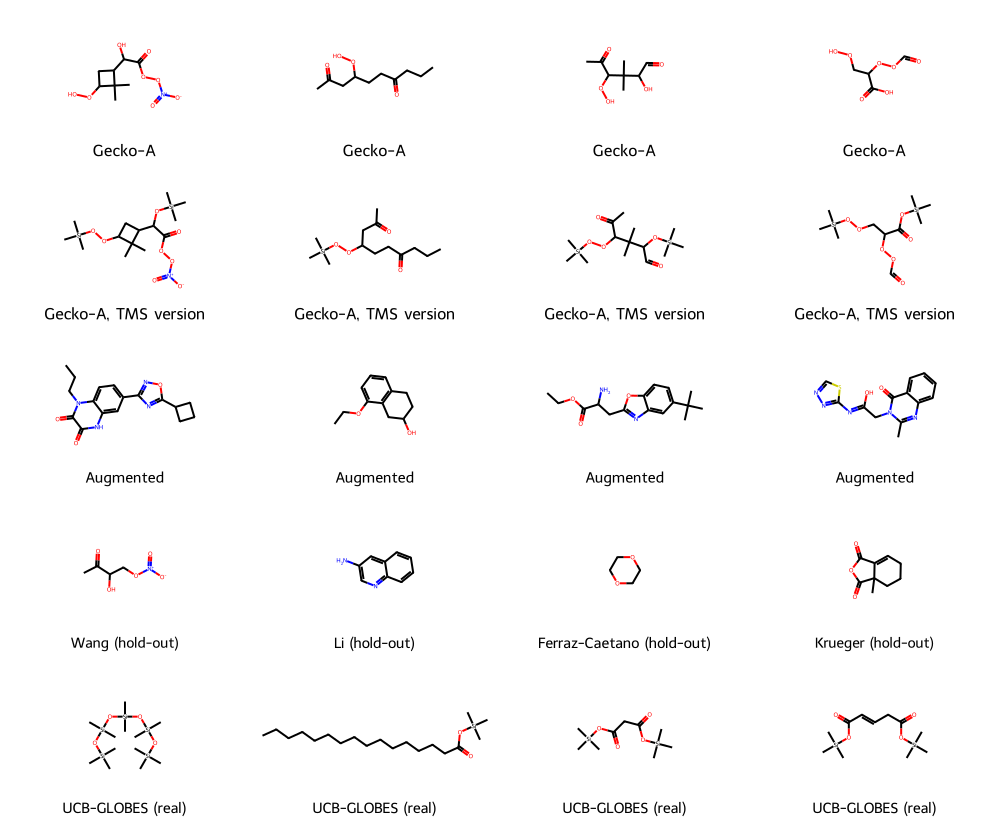

In [3]:
def pick_examples():
    "Random molecules with at most 30 heavy atoms, so that they can be drawn at a readable size."
    plain, tms = read_split(PLAIN_DIR), read_split(TMS_DIR).set_index('spec')
    rng = np.random.default_rng(SEED)
    small = lambda s: Chem.MolFromSmiles(s).GetNumHeavyAtoms() <= 30

    def sample(df, k):
        out, idx = [], rng.permutation(len(df))
        for i in idx:
            r = df.iloc[int(i)]
            if small(r['smiles']):
                out.append(r)
            if len(out) == k:
                return out

    # Gecko-A pairs: gecko_new_<i> and gecko_new_tms_<i> are the same molecule. Only pairs that were derivatised.
    gecko = plain[(plain['group'] == 'Gecko-A') & (plain['split'] == 'train')]
    gecko = gecko[gecko['spec'].str.replace('gecko_new_', 'gecko_new_tms_').isin(tms.index)]
    pairs = []
    for r in sample(gecko, 40):
        t = tms.loc[r['spec'].replace('gecko_new_', 'gecko_new_tms_')]
        if t['formula'] != r['formula'] and small(t['smiles']) and len(pairs) < 4:
            pairs.append((r['smiles'], t['smiles']))
    aug = [r['smiles'] for r in sample(plain[(plain['group'] == 'Augmented') & (plain['split'] == 'train')], 4)]
    hold = {g: sample(plain[plain['group'] == g], 1)[0]['smiles'] for g in HOLD_OUT.values()}
    real = [Chem.MolToSmiles(m) for m in refs['mol'].sample(4, random_state=SEED)]
    return {'pairs': pairs, 'aug': aug, 'hold': hold, 'real': real}


ex = cached('examples', pick_examples)
rows = [([p for p, _ in ex['pairs']], 'Gecko-A'), ([t for _, t in ex['pairs']], 'Gecko-A, TMS version'),
        (ex['aug'], 'Augmented'), (list(ex['hold'].values()), None), (ex['real'], 'UCB-GLOBES (real)')]
mols, legends = [], []
for smiles, label in rows:
    for i, s in enumerate(smiles):
        mols.append(Chem.MolFromSmiles(s))
        legends.append(label or f'{list(ex["hold"])[i]} (hold-out)'.replace('ü', 'ue'))    # the RDKit legend font has no ü
display(Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(250, 165), legends=legends))

## 3. How the chemistry differs

All molecules are shown underivatised here, with TMS groups removed from the UCB-GLOBES references, so that the sets compare directly.

- **Size:** training molecules are larger, with a median of 18 and 25 heavy atoms against 10–14 in both test sets.
- **Gecko-A is narrow:** only CHO and CHON, no aromatic rings, and many peroxides and nitrates.
- **Augmented adds what Gecko-A lacks:** aromatic rings, sulfur and halogens.
- **Hold-out sets differ from each other:** for example, Li is mostly sulfur-containing and Krüger has no nitrogen.
- **UCB-GLOBES is simpler:** over 90% CHO, rich in acids, hydroxyls and aromatic rings.

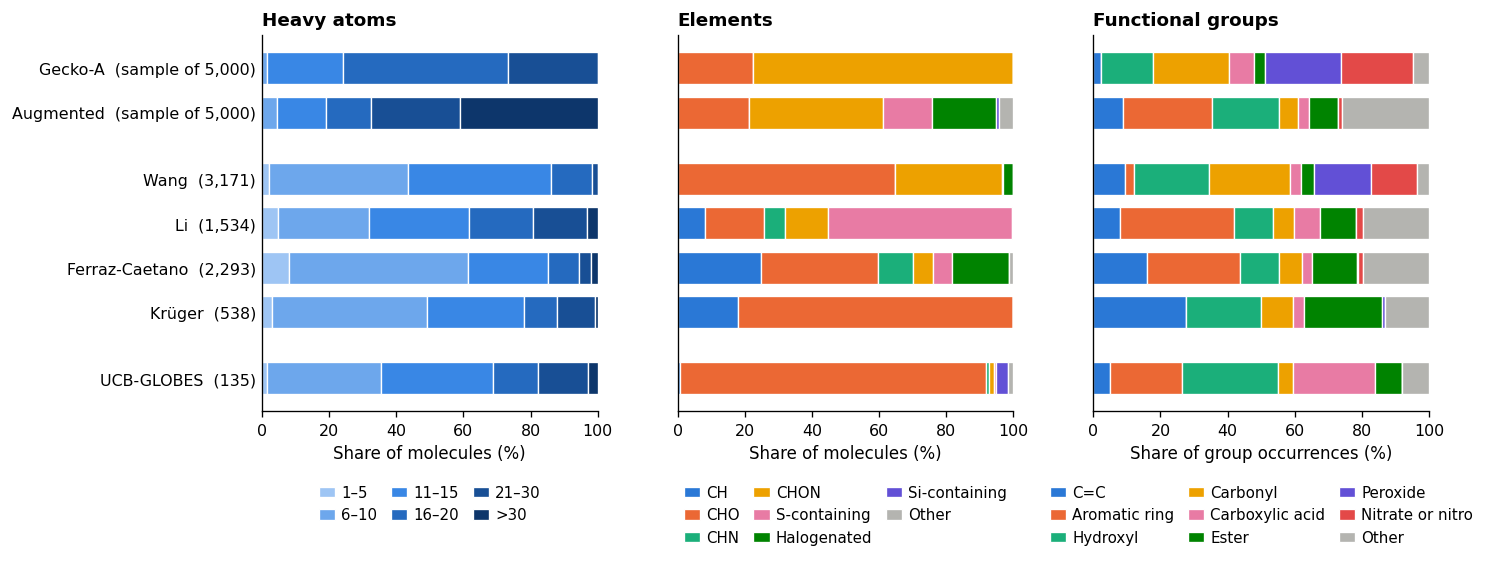

Median heavy atoms: {'Gecko-A': 18, 'Augmented': 25, 'Wang': 11, 'Li': 13, 'Ferraz-Caetano': 10, 'Krüger': 11, 'UCB-GLOBES': 12}


In [4]:
ATMO_NAMES = pd.read_csv('explained_atmo_patterns_v5.csv', index_col=0)['Name'].tolist()
FUNCTIONAL_GROUPS = {   # as test_set_overview.ipynb
    'C=C': ['C=C (non-aromatic)'], 'Aromatic ring': ['aromatic ring'], 'Hydroxyl': ['hydroxyl (alkyl)', 'aromatic hydroxyl'],
    'Carbonyl': ['ketone', 'aldehyde'], 'Carboxylic acid': ['carboxylic acid'], 'Ester': ['ester, all'],
    'Peroxide': ['peroxide', 'hydroperoxide', 'carbonylperoxyacid'],
    'Nitrate or nitro': ['nitrate', 'carbonylperoxynitrate', 'peroxy nitrate', 'nitro', 'nitrophenol', 'nitroester'],
    'Other': ['ether', 'ether, aromatic', 'ether (alicyclic)', 'amine, primary', 'amine, secondary', 'amine, tertiary',
              'amine, aromatic', 'amide', 'organosulfate'],
}
HA_BINS, HA_LABELS = [0, 5, 10, 15, 20, 30, np.inf], ['1–5', '6–10', '11–15', '16–20', '21–30', '>30']
ELEMENT_CLASSES = ['CH', 'CHO', 'CHN', 'CHON', 'S-containing', 'Halogenated', 'Si-containing', 'Other']
HALOGENS = {'F', 'Cl', 'Br', 'I'}


def element_class(mol):
    elements = {a.GetSymbol() for a in mol.GetAtoms()} - {'C', 'H'}
    if 'Si' in elements:
        return 'Si-containing'
    if elements - {'O', 'N', 'S'} - HALOGENS:
        return 'Other'
    if elements & HALOGENS:
        return 'Halogenated'
    if 'S' in elements:
        return 'S-containing'
    return 'CH' + ''.join(e for e in 'ON' if e in elements)


def describe(mol):
    keys = dict(zip(ATMO_NAMES, pyGenATMOKeys(mol)))
    groups = {g: any(keys[k] > 0 for k in names) for g, names in FUNCTIONAL_GROUPS.items()}
    return {'heavy': mol.GetNumHeavyAtoms(), 'element_class': element_class(mol), **groups}


def compute_composition():
    plain = read_split(PLAIN_DIR)
    used = plain[plain['split'].isin(['train', 'test'])]
    parts = [used[used['group'] == g] for g in HOLD_OUT.values()]
    parts += [used[used['group'] == g].sample(N_COMPOSITION, random_state=SEED) for g in ('Gecko-A', 'Augmented')]
    rows = [{'group': r.group, **describe(Chem.MolFromSmiles(r.smiles))} for r in pd.concat(parts).itertuples()]
    # Reference spectra whose structure matches the spectrum's formula, described as the underivatised parent
    ok = refs[[CalcMolFormula(m) == f for m, f in zip(refs['mol'], refs['formula'])]]
    rows += [{'group': 'UCB-GLOBES', **describe(remove_tms(m))} for m in ok['mol']]
    return pd.DataFrame(rows)


comp = cached('composition', compute_composition)
comp['ha_bin'] = pd.cut(comp['heavy'], HA_BINS, labels=HA_LABELS)
n = comp['group'].value_counts()
YPOS = dict(zip(GROUPS, [0, 1, 2.5, 3.5, 4.5, 5.5, 7]))     # gaps between training, hold-out and real
ylabels = [f"{g}  ({'sample of ' if g in ('Gecko-A', 'Augmented') else ''}{n[g]:,})" for g in GROUPS]


def stacked(ax, pct, colors, title, xlabel, ncol):
    y, left = np.array([YPOS[g] for g in GROUPS]), np.zeros(len(GROUPS))
    pct = pct.reindex(GROUPS)
    for c, color in zip(pct.columns, colors):
        ax.barh(y, pct[c], left=left, height=0.72, color=color, edgecolor='white', linewidth=0.8, label=c)
        left += pct[c].to_numpy()
    ax.set(xlim=(0, 100), xlabel=xlabel)
    ax.set_title(title)
    ax.invert_yaxis() if not ax.yaxis_inverted() else None
    ax.tick_params(axis='y', length=0)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=ncol, columnspacing=0.9, handlelength=1.1, handletextpad=0.4)


fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.9), sharey=True)
to_pct = lambda t: t.div(t.sum(axis=1), axis=0) * 100
stacked(axes[0], to_pct(pd.crosstab(comp['group'], comp['ha_bin']).reindex(columns=HA_LABELS, fill_value=0)), SEQUENTIAL,
        'Heavy atoms', 'Share of molecules (%)', 3)
stacked(axes[1], to_pct(pd.crosstab(comp['group'], comp['element_class']).reindex(columns=ELEMENT_CLASSES, fill_value=0)),
        CATEGORICAL[:7] + [NEUTRAL], 'Elements', 'Share of molecules (%)', 3)
stacked(axes[2], to_pct(comp.groupby('group')[list(FUNCTIONAL_GROUPS)].sum()), CATEGORICAL + [NEUTRAL],
        'Functional groups', 'Share of group occurrences (%)', 3)
axes[0].set_yticks([YPOS[g] for g in GROUPS], ylabels)
plt.tight_layout()
plt.show()
print('Median heavy atoms:', comp.groupby('group')['heavy'].median().reindex(GROUPS).astype(int).to_dict())

## 4. How far is the test chemistry from training?

For each test molecule, we find its most similar molecule in each training set, using the Morgan fingerprint the encoder is pretrained on. Dashed lines mark the medians.

- **Hold-out is far from training:** the median nearest neighbour is at 0.39 to Gecko-A and 0.53 to Augmented, and few molecules have a close neighbour.
- **Augmented is the closer set,** even though Gecko-A is the atmospheric one.
- **UCB-GLOBES compounds are closer,** with a median of 0.75 to Augmented.

A Tanimoto of 1 does not mean the same structure. This fingerprint is identical for some different molecules, such as palmitic and stearic acid. That explains the spike at 1, since the counts by InChIKey below are much lower.

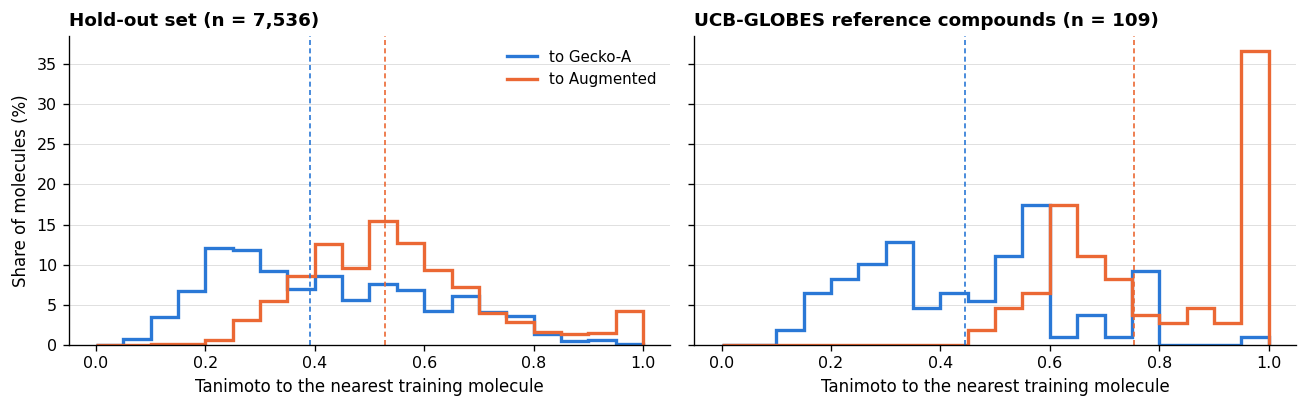

            median to Gecko-A  median to Augmented
query                                             
Hold-out                 0.39                 0.53
UCB-GLOBES               0.44                 0.75

Hold-out: 11% have a training neighbour at 0.8 or above. Augmented is the closer set for 68%.
Same structure in training, by InChIKey: 0 of the hold-out set; 15 UCB-GLOBES compounds; in their TMS form, in TMS training, 21 of 107.


In [5]:
POP16 = np.array([bin(i).count('1') for i in range(1 << 16)], dtype=np.uint8)
_train = {}


def packed_fp(smiles):
    "2048-bit Morgan fingerprint (r = 2) as 128 uint16 values, the fingerprint the encoder is pretrained on."
    fp = AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(smiles), 2, nBits=2048)
    return np.packbits(np.frombuffer(fp.ToBitString().encode(), dtype=np.uint8) - 48).view(np.uint16)


def nearest(q):
    "Highest Tanimoto of fingerprint q to each training set, in chunks to keep memory use flat."
    out = {}
    nq = POP16[q].sum(dtype=np.int64)
    for name, (X, nx) in _train.items():
        best = 0.0
        for i in range(0, len(X), 8192):
            inter = POP16[X[i:i + 8192] & q].sum(axis=1, dtype=np.int32)
            best = max(best, float((inter / (nq + nx[i:i + 8192] - inter)).max()))
        out[name] = best
    return out


def compute_nearest():
    plain = read_split(PLAIN_DIR)
    with mp.Pool(N_WORKERS) as pool:
        for g in ('Gecko-A', 'Augmented'):
            s = plain[(plain['group'] == g) & (plain['split'] == 'train')]['smiles'].drop_duplicates()
            X = np.stack(pool.map(packed_fp, s.tolist(), chunksize=2000))
            _train[g] = (X, POP16[X].sum(axis=1, dtype=np.int32))
    held = plain[plain['split'] == 'test']
    parents = pd.Series([Chem.MolToSmiles(remove_tms(m)) for m in refs['mol']]).drop_duplicates()
    queries = [('Hold-out', s) for s in held['smiles']] + [('UCB-GLOBES', s) for s in parents]
    fps = [packed_fp(s) for _, s in queries]
    with mp.Pool(N_WORKERS) as pool:       # forked after _train is filled, so workers share it
        res = pool.map(nearest, fps, chunksize=50)
    return pd.DataFrame(res).assign(query=[k for k, _ in queries])


def shared_structures():
    "Structures in common by first InChIKey block, for the underivatised and the TMS data."
    plain, tms = read_split(PLAIN_DIR), read_split(TMS_DIR)
    blocks = lambda df, split: set(df.loc[df['split'] == split, 'inchikey'].str[:14])
    parents = {Chem.MolToInchiKey(remove_tms(m))[:14] for m in refs['mol']}
    derivatives = set(refs['block'])
    return {'hold-out in training': len(blocks(plain, 'test') & blocks(plain, 'train')),
            'hold-out, TMS version, in training': len(blocks(tms, 'test') & blocks(tms, 'train')),
            'reference compounds': len(derivatives), 'references in TMS training': len(derivatives & blocks(tms, 'train')),
            'references in TMS hold-out': len(derivatives & blocks(tms, 'test')), 'parents in training': len(parents & blocks(plain, 'train'))}


nn = cached('nearest_training_molecule', compute_nearest)
shared = cached('shared_structures', shared_structures)
bins = np.arange(0, 1.0001, 0.05)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True, sharex=True)
for ax, (q, title) in zip(axes, (('Hold-out', 'Hold-out set'), ('UCB-GLOBES', 'UCB-GLOBES reference compounds'))):
    x = nn[nn['query'] == q]
    for g, color in (('Gecko-A', C1), ('Augmented', C2)):
        h, _ = np.histogram(x[g], bins=bins)
        ax.stairs(h / len(x) * 100, bins, color=color, linewidth=2, label=f'to Gecko-A' if g == 'Gecko-A' else 'to Augmented')
        m = x[g].median()
        ax.axvline(m, color=color, linewidth=1, linestyle=(0, (3, 2)))
    ax.set_title(f'{title} (n = {len(x):,})')
    ax.set_xlabel('Tanimoto to the nearest training molecule')
    ax.grid(axis='y', **GRID_KW)
axes[0].set_ylabel('Share of molecules (%)')
axes[0].legend(loc='upper right')
plt.tight_layout()
plt.show()
print(nn.groupby('query')[['Gecko-A', 'Augmented']].median().round(2).rename(columns=lambda c: f'median to {c}').to_string())
_best = nn[['Gecko-A', 'Augmented']].max(axis=1)
print(f"\nHold-out: {(_best[nn['query'] == 'Hold-out'] >= 0.8).mean():.0%} have a training neighbour at 0.8 or above. "
      f"Augmented is the closer set for {(nn.loc[nn['query'] == 'Hold-out', 'Augmented'] > nn.loc[nn['query'] == 'Hold-out', 'Gecko-A']).mean():.0%}.")
print(f"Same structure in training, by InChIKey: {shared['hold-out in training']} of the hold-out set; "
      f"{shared['parents in training']} UCB-GLOBES compounds; in their TMS form, in TMS training, "
      f"{shared['references in TMS training']} of {shared['reference compounds']}.")

## 5. Are simulated spectra close to real ones?

This matters most, because the model only ever learns from the simulator. For compounds with both a measured and a simulated spectrum (TMS versions), we compare them with cosine similarity on unit m/z and square-root intensity, from m/z 35 up.

- **Right panel:** the simulator's median of 0.83 is well above unrelated compounds at 0.53, but below repeat measurements at 0.95, which is about the ceiling. Unrelated compounds still score high, probably in part because TMS derivatives share ions such as m/z 73.
- **Left panel:** catechol 2TMS sits at the median of that distribution, so it is a fair example. NEIMS gets the base peak right, but it strongly overestimates M+. and [M-CH3]+. Those are the peaks that separate catechol from hydroquinone in the next notebook.

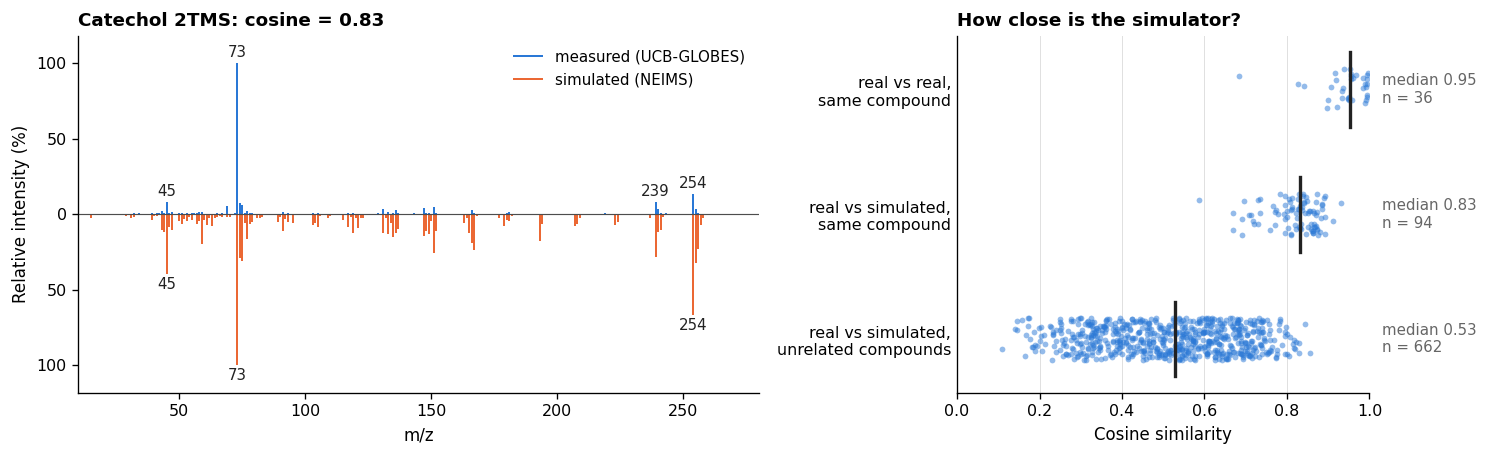

94 of 135 reference spectra have a simulated counterpart in our data; catechol is at percentile 51 of those.
Catechol M+. (m/z 254): 14% measured, 67% simulated. m/z 239: 8% measured, 28% simulated.


In [6]:
EXAMPLE = 'LDY-20562'   # catechol 2TMS, near the median below and the worked example of the walkthrough
MZ_MIN = 35             # real spectra start near m/z 30, simulated ones at 15


def simulated_counterparts():
    "NEIMS spectra of the TMS structures that also have a real reference spectrum."
    lab = read_split(TMS_DIR)
    lab['block'] = lab['inchikey'].str[:14]
    want = lab[lab['block'].isin(set(refs['block']))]
    names, sim = set(want['spec']), {}
    for f in ('atmomaccs_new/spectra_combined_tms.mgf', 'gecko_tms/mist_inputs/spectra.mgf', 'mixed_augment_tms/spectra.mgf'):
        cur = None
        for line in open(f'{NEIMS}/{f}'):
            if line.startswith('FEATURE_ID='):
                n_ = line[11:].strip()
                cur, peaks = (n_ if n_ in names else None), []
            elif cur and line[0].isdigit():
                peaks.append([float(v) for v in line.split()])
            elif cur and line.startswith('END'):
                sim[cur] = np.array(peaks)
                cur = None
    return {'sim': sim, 'blocks': want.groupby('block')['spec'].apply(list).to_dict(),
            'split': want.groupby('split').size().to_dict()}


sim_data = cached('simulated_counterparts', simulated_counterparts)
spec_df = pd.read_pickle(f'{YEE_DIR}/df_neims_yee_3_9_22.pkl').set_index('name')
real_of = {u: np.asarray(spec_df.loc[u, 'spec'], dtype=float) for u in refs.index}


def unit_vector(peaks):
    "Unit m/z, square-root intensity, L2-normalised."
    v = np.zeros(1000)
    for mz, i in peaks:
        if MZ_MIN <= mz < 1000:
            v[int(round(mz))] += i
    v = np.sqrt(v)
    return v / np.linalg.norm(v)


R = {u: unit_vector(p) for u, p in real_of.items()}
S = {b: unit_vector(sim_data['sim'][names_[0]]) for b, names_ in sim_data['blocks'].items()}
rng = np.random.default_rng(SEED)
blocks = list(S)
same = {u: float(R[u] @ S[r]) for u, r in refs['block'].items() if r in S}
other = [float(R[u] @ S[b]) for u, r in refs['block'].items() for b in rng.choice(blocks, 5, replace=False) if b != r]
repeat = [float(R[a] @ R[b]) for a, b in combinations(refs.index, 2) if refs.loc[a, 'block'] == refs.loc[b, 'block']]
strips = {'real vs real,\nsame compound': repeat, 'real vs simulated,\nsame compound': list(same.values()), 'real vs simulated,\nunrelated compounds': other}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), gridspec_kw={'width_ratios': [1.65, 1]})
ax = axes[0]
sim_ex = sim_data['sim'][sim_data['blocks'][refs.loc[EXAMPLE, 'block']][0]]
for peaks, sign, color, label in ((real_of[EXAMPLE], 1, C1, 'measured (UCB-GLOBES)'), (sim_ex, -1, C2, 'simulated (NEIMS)')):
    mz, inten = peaks[:, 0], peaks[:, 1] / peaks[:, 1].max() * 100
    ax.vlines(mz, 0, sign * inten, color=color, linewidth=1.2, label=label)
    done = []
    for i in np.argsort(-inten)[:5]:
        if all(abs(mz[i] - m) >= 4 for m in done):
            done.append(mz[i])
            ax.text(mz[i], sign * (inten[i] + 2), f'{mz[i]:.0f}', ha='center', va='bottom' if sign > 0 else 'top', fontsize=9, color=INK)
ax.axhline(0, color='0.3', linewidth=0.7)
ax.set(xlim=(10, 280), ylim=(-118, 118), xlabel='m/z', ylabel='Relative intensity (%)')
ax.set_yticks([-100, -50, 0, 50, 100], [100, 50, 0, 50, 100])
ax.set_title(f'Catechol 2TMS: cosine = {same[EXAMPLE]:.2f}')
ax.legend(loc='upper right')

ax = axes[1]
for i, (k, v) in enumerate(strips.items()):
    v = np.array(v)
    ax.scatter(v, i + rng.uniform(-0.17, 0.17, len(v)), s=12, color=C1, alpha=0.5, linewidths=0)
    ax.plot([np.median(v)] * 2, [i - 0.3, i + 0.3], color=INK, linewidth=2)
    ax.text(1.03, i, f'median {np.median(v):.2f}\nn = {len(v):,}', va='center', fontsize=9, color=MUTED)
ax.set_yticks(range(3), list(strips))
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel='Cosine similarity')
ax.set_title('How close is the simulator?')
ax.grid(axis='x', **GRID_KW)
ax.tick_params(axis='y', length=0)
plt.tight_layout()
plt.show()
print(f'{len(same)} of {len(refs)} reference spectra have a simulated counterpart in our data; '
      f'catechol is at percentile {np.mean(np.array(list(same.values())) < same[EXAMPLE]) * 100:.0f} of those.')
_at = lambda peaks, z: peaks[peaks[:, 0] == z, 1].sum() / peaks[:, 1].max() * 100
print(f'Catechol M+. (m/z 254): {_at(real_of[EXAMPLE], 254):.0f}% measured, {_at(sim_ex, 254):.0f}% simulated. '
      f'm/z 239: {_at(real_of[EXAMPLE], 239):.0f}% measured, {_at(sim_ex, 239):.0f}% simulated.')

**In short**

- Training is large (454k spectra) but entirely simulated.
- The test molecules are smaller than the training molecules and chemically different from them, and the hold-out set shares no structure with training.
- Real spectra add a gap that the hold-out test cannot show: the simulator is good, but not equal to a measurement. Only 135 real spectra can be scored.

The next notebook shows what the model does with these data.